
# Lab Exercise 8 — Probabilistic Programming with PyMC

## Problem Description

A store receives an unknown number of customers, called **n**.

Each customer has a probability **theta** of buying a product.

The number of customers who purchase the product is **Y**.

We use:

- **n:** Total number of customers (unknown).
- **Y:** Number of purchases (observed).
- **theta:** Probability that a customer buys the product (known).

### Probability Distributions

**Prior:**

$$
n \sim Poisson(10)
$$

**Likelihood:**

$$
Y \mid n,\theta \sim Binomial(n,\theta)
$$

**Goal:** Estimate the posterior distribution of n after observing Y.

We will test:

- Y = 0, 5, 10
- theta = 0.2, 0.5

This gives 6 combinations.


In [67]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

# Values provided in the exercise
Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]

# Prior mean
prior_mean = 10

# Display all combinations
for Y in Y_values:
    for theta in theta_values:
        print(f"Y = {Y}, theta = {theta}")


Y = 0, theta = 0.2
Y = 0, theta = 0.5
Y = 5, theta = 0.2
Y = 5, theta = 0.5
Y = 10, theta = 0.2
Y = 10, theta = 0.5



## Posterior Distributions for All Combinations

We now calculate the posterior distribution of n for all combinations:

- Y = 0, 5, 10
- theta = 0.2, 0.5

We use the same Bayesian model for each combination:

- **Prior:** n ~ Poisson(10)
- **Likelihood:** Y ~ Binomial(n, theta)

We save the posterior samples to compare the results later.


In [68]:
# Improve convergence using 4 chains

traces = {}

for Y in Y_values:
    for theta in theta_values:

        with pm.Model() as model:
            # Prior
            n = pm.Poisson("n", mu=10)

            # Likelihood
            purchases = pm.Binomial(
                "purchases",
                n=n,
                p=theta,
                observed=Y
            )

            # Sample posterior
            step = pm.Metropolis(vars=[n])

            result = pm.sample(
                draws=2000,
                tune=2000,
                chains=4,
                cores=1,
                step=step,
                initvals={"n": max(10, Y)},
                random_seed=42,
                progressbar=False
            )

        traces[(Y, theta)] = result

        # Check convergence
        summary = az.summary(result, var_names=["n"])

        print(
            f"Y={Y}, theta={theta}: "
            f"mean={summary.loc['n', 'mean']:.2f}, "
            f"R-hat={summary.loc['n', 'r_hat']:.3f}"
        )


Sequential sampling (4 chains in 1 job)
Metropolis: [n]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Y=0, theta=0.2: mean=8.04, R-hat=1.001


Sequential sampling (4 chains in 1 job)
Metropolis: [n]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Y=0, theta=0.5: mean=5.08, R-hat=1.001


Sequential sampling (4 chains in 1 job)
Metropolis: [n]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Y=5, theta=0.2: mean=13.08, R-hat=1.003


... (2 outputs left out)

Metropolis: [n]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Sequential sampling (4 chains in 1 job)
Metropolis: [n]


Y=10, theta=0.2: mean=18.01, R-hat=1.001


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Y=10, theta=0.5: mean=15.08, R-hat=1.003



## Posterior Visualization — All Combinations

We visualize the posterior distributions of the total number of customers for all six combinations.

- Y = 0, 5, 10
- theta = 0.2, 0.5

Each plot shows:
- The posterior distribution of n.
- The estimated posterior mean.
- The 94% Highest Density Interval (HDI).

We use ArviZ to display all six posterior distributions in a single figure.


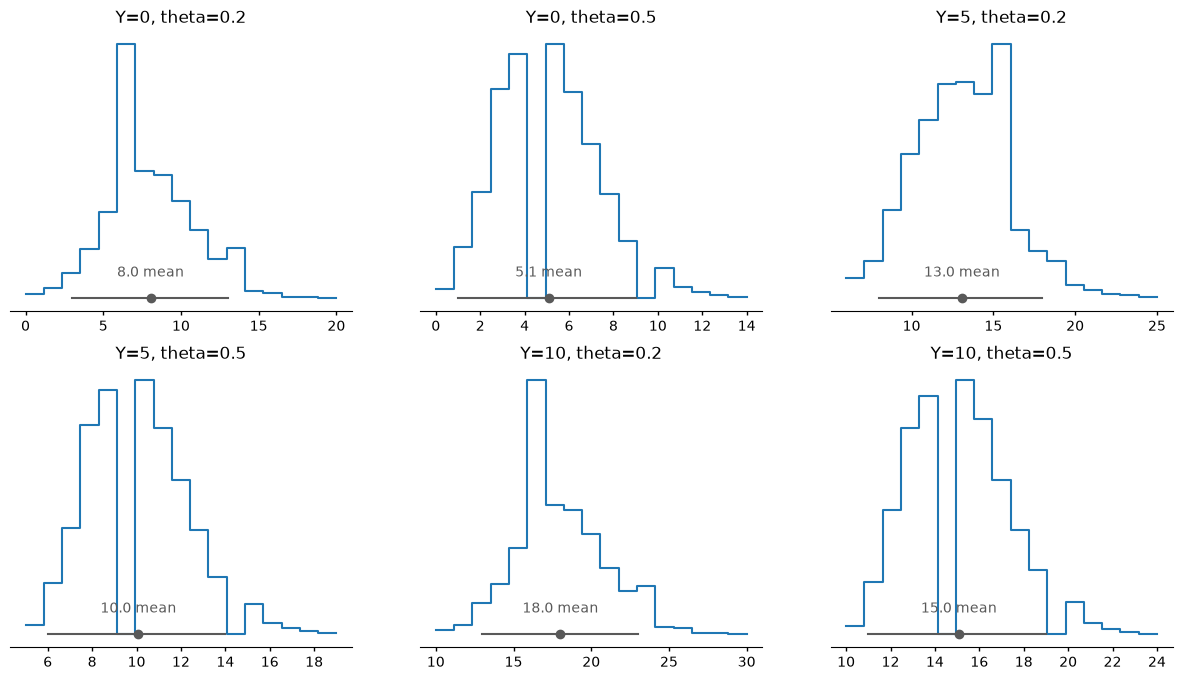

In [69]:

import xarray as xr
import arviz_plots as azp

# Prepare labels for the six combinations
case_labels = [
    f"Y={Y}, theta={theta}"
    for Y in Y_values
    for theta in theta_values
]

# Combine posterior samples into one dataset
samples = np.stack([
    traces[(Y, theta)].posterior["n"].values
    for Y in Y_values
    for theta in theta_values
], axis=-1)

posterior_ds = xr.Dataset(
    {"n": (("chain", "draw", "case"), samples)},
    coords={"case": case_labels}
)

combined_trace = xr.DataTree.from_dict({
    "posterior": posterior_ds
})

# Plot all six posterior distributions
azp.plot_dist(
    combined_trace,
    var_names=["n"],
    kind="hist",
    ci_kind="hdi",
    ci_prob=0.94,
    cols=["case"],
    col_wrap=3,
    figure_kwargs={"figsize": (15, 8)}
)

plt.show()



## Convergence Diagnostics

We check R-hat to verify that the MCMC chains have converged.

- R-hat close to 1 indicates good agreement between chains.
- R-hat above 1.01 may indicate convergence problems.
- We use 4 chains and more samples to improve the reliability of the results.

The posterior means should be close to the theoretical values.


## Effect of Y and Theta on the Posterior Distribution

### Effect of Y (Number of Purchases)

When **Y increases**, the posterior distribution moves to higher values of n.

This happens because more purchases suggest that more customers visited the store.

### Effect of Theta (Purchase Probability)

When **theta increases**, the posterior distribution moves to lower values of n for the same Y.

This happens because, if each customer is more likely to buy, fewer total customers are needed to explain the observed purchases.

### Conclusion

- Higher Y means more estimated customers.
- Higher theta means fewer estimated customers for the same Y.
- The posterior distribution combines the prior information with the observed purchases.
- The posterior also represents uncertainty about the total number of customers.
